<center><h1>Comparing Kinetic Parameters</h1></center><hr/>

In [1]:
from scripts.utils import *

### Analyze the Gathered and Estimated Kinetic Parameters

In [2]:
reactions_kinetics = pd.ExcelFile(KINETIC_PARAMETERS_PATH)

gathered_kinetics = pd.read_excel(reactions_kinetics, 'Gathered_Final', header = [0, 1])
estimated_kinetics = pd.read_excel(reactions_kinetics, 'Estimated', header = [0, 1, 2])

#### Gathered Kinetics

In [3]:
gathered_kinetics.replace("/", np.nan, inplace=True)

In [4]:
gathered_kinetics.head()

Unnamed: 0_level_0                BRENDA                     \
            reaction              organism km (mM) kcat (1/s)   
0            rx00001   Catharanthus roseus     0.1        NaN   
1            rx00002  Solanum lycopersicum  0.0315       1.41   
2            rx00003                   NaN     NaN        NaN   
3            rx00014                  /\n/    /\n/       /\n/   
4            rx00020  Solanum lycopersicum     2.3        NaN   

               SABIO-RK                     
               organism km (mM) kcat (1/s)  
0      Escherichia coli    0.11        1.5  
1  Arabidopsis thaliana   0.023        NaN  
2      Persea americana  0.0533          3  
3                  /\n/    /\n/       /\n/  
4  Arabidopsis thaliana    7.64        NaN

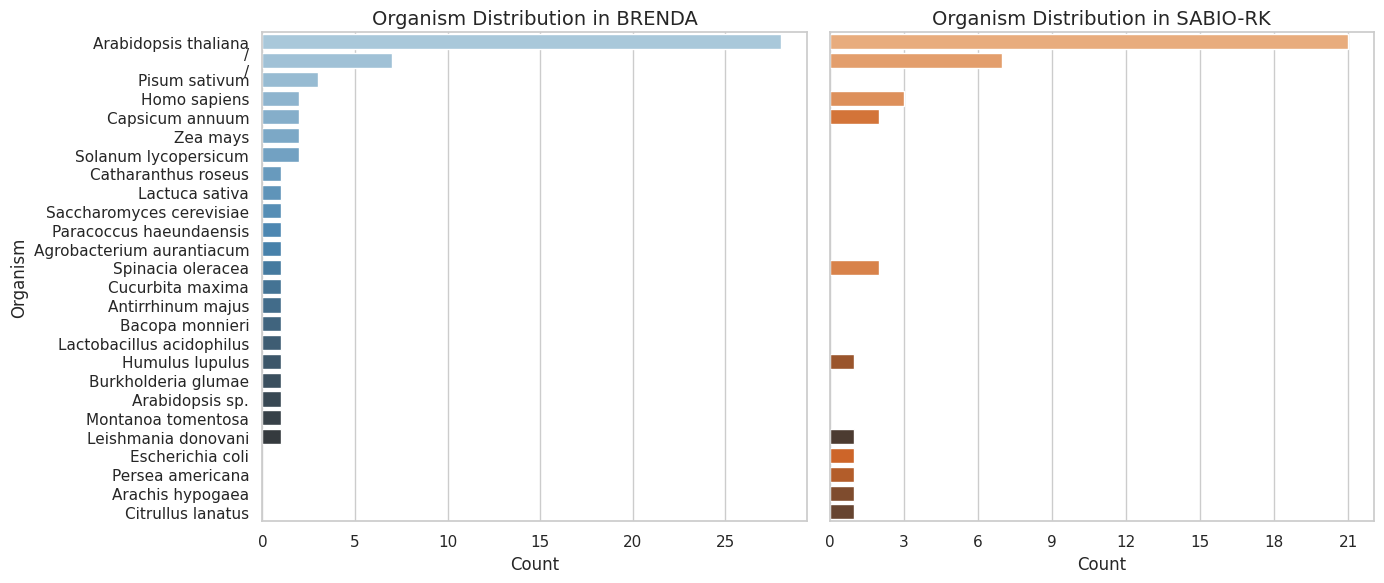

In [5]:
# Prepare the data
brenda_counts = gathered_kinetics['BRENDA']['organism'].value_counts().reset_index()
brenda_counts.columns = ['Organism', 'Count']

sabio_counts = gathered_kinetics['SABIO-RK']['organism'].value_counts().reset_index()
sabio_counts.columns = ['Organism', 'Count']

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# BRENDA plot
sns.barplot(data=brenda_counts, y='Organism', x='Count', hue='Organism', ax=axes[0], palette='Blues_d', dodge=False, legend=False)
axes[0].set_title("Organism Distribution in BRENDA", fontsize=14)
axes[0].set_xlabel("Count", fontsize=12)
axes[0].set_ylabel("Organism", fontsize=12)

# SABIO-RK plot
sns.barplot(data=sabio_counts, y='Organism', x='Count', hue='Organism', ax=axes[1], palette='Oranges_d', dodge=False, legend=False)
axes[1].set_title("Organism Distribution in SABIO-RK", fontsize=14)
axes[1].set_xlabel("Count", fontsize=12)
axes[1].set_ylabel("")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))  # Force integer ticks

# Adjust layout
plt.tight_layout()
plt.show()


In [6]:
print(f"Missing information in BRENDA:   {gathered_kinetics['BRENDA']['organism'].isna().sum()}  - {gathered_kinetics['BRENDA']['organism'].isna().sum()/len(gathered_kinetics)*100:.2f}%")
print(f"Missing information in SABIO-RK: {gathered_kinetics['SABIO-RK']['organism'].isna().sum()} - {gathered_kinetics['SABIO-RK']['organism'].isna().sum()/len(gathered_kinetics)*100:.2f}%")

Missing information in BRENDA:   84  - 57.93%
Missing information in SABIO-RK: 104 - 71.72%


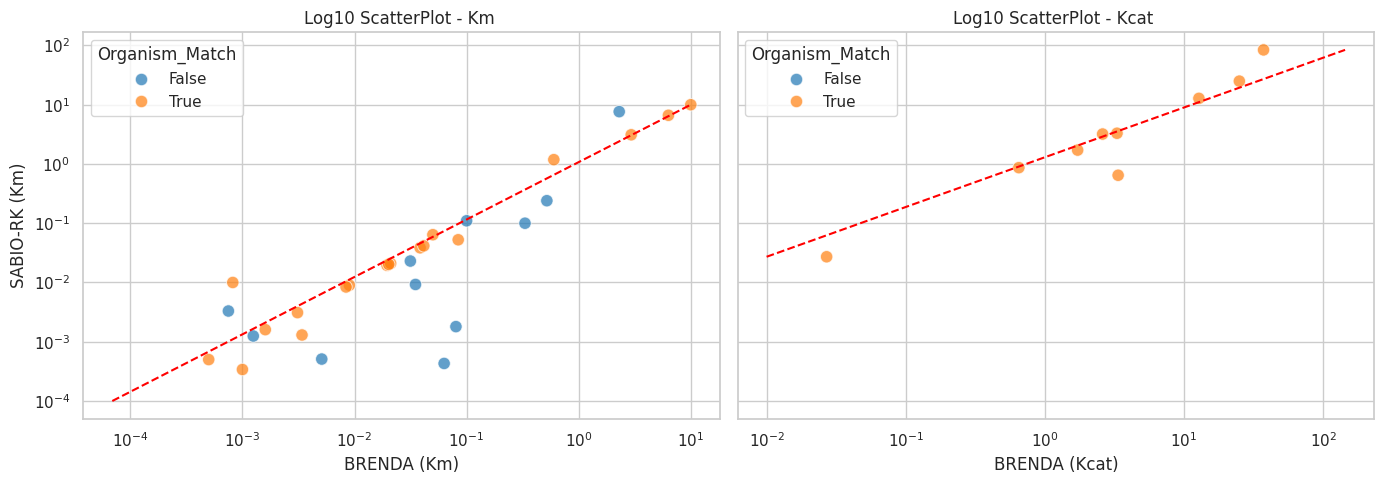

Shared measurements:          30 Km,  9  Kcat
BRENDA unique measurements:   21 Km,  14 Kcat
SABIO-RK unique measurements: 4  Km,  4  Kcat


In [7]:
fig, ax = plt.subplots(1, 2, figsize = (14, 5), sharey = True)

brenda_km = pd.to_numeric(gathered_kinetics[('BRENDA', 'km (mM)')], errors='coerce')
sabio_km = pd.to_numeric(gathered_kinetics[('SABIO-RK', 'km (mM)')], errors='coerce')

brenda_kcat = pd.to_numeric(gathered_kinetics[('BRENDA', 'kcat (1/s)')], errors='coerce')
sabio_kcat = pd.to_numeric(gathered_kinetics[('SABIO-RK', 'kcat (1/s)')], errors='coerce')


df = pd.DataFrame({
    'BRENDA_km': brenda_km, 
    'SABIO-RK_km': sabio_km, 
    'BRENDA_kcat': brenda_kcat, 
    'SABIO-RK_kcat': sabio_kcat,
    'Organism_Match': gathered_kinetics[('BRENDA', 'organism')] == gathered_kinetics[('SABIO-RK', 'organism')]
    
})#.fillna(0) #.dropna()

# — Scatter (log–log)
sns.scatterplot(data = df, x = 'BRENDA_km', y = 'SABIO-RK_km', hue='Organism_Match', s=80, alpha=0.7, ax=ax[0], palette=['#1f77b4', '#ff7f0e'])
ax[0].plot([df["BRENDA_km"].min(), df["BRENDA_km"].max()], [df['SABIO-RK_km'].min(), df['SABIO-RK_km'].max()], '--', color = 'red')
ax[0].set_xlabel(f'BRENDA (Km)')
ax[0].set_ylabel(f'SABIO-RK (Km)')
ax[0].set_title(f'Log10 ScatterPlot - Km ')

ax[0].set_xscale('log')
ax[0].set_yscale('log')


sns.scatterplot(data = df, x = 'BRENDA_kcat', y = 'SABIO-RK_kcat', hue='Organism_Match', s=80, alpha=0.7, ax=ax[1], palette=['#1f77b4', '#ff7f0e'])
ax[1].plot([df["BRENDA_kcat"].min(), df["BRENDA_kcat"].max()], [df['SABIO-RK_kcat'].min(), df['SABIO-RK_kcat'].max()], '--', color = 'red')
ax[1].set_xlabel(f'BRENDA (Kcat)')
ax[1].set_ylabel(f'SABIO-RK (Kcat)')
ax[1].set_title(f'Log10 ScatterPlot - Kcat ')

ax[1].set_xscale('log')
ax[1].set_yscale('log')

plt.tight_layout()
plt.show()


# Print statistics
print(f"Shared measurements:          {df[['BRENDA_km', 'SABIO-RK_km']].dropna().shape[0]} Km,  {df[['BRENDA_kcat', 'SABIO-RK_kcat']].dropna().shape[0]}  Kcat")
print(f"BRENDA unique measurements:   {df['BRENDA_km'].count() - df[['BRENDA_km', 'SABIO-RK_km']].dropna().shape[0]} Km,  {df['BRENDA_kcat'].count() - df[['BRENDA_kcat', 'SABIO-RK_kcat']].dropna().shape[0]} Kcat")
print(f"SABIO-RK unique measurements: {df['SABIO-RK_km'].count() - df[['BRENDA_km', 'SABIO-RK_km']].dropna().shape[0]}  Km,  {df['SABIO-RK_kcat'].count() - df[['BRENDA_kcat', 'SABIO-RK_kcat']].dropna().shape[0]}  Kcat")

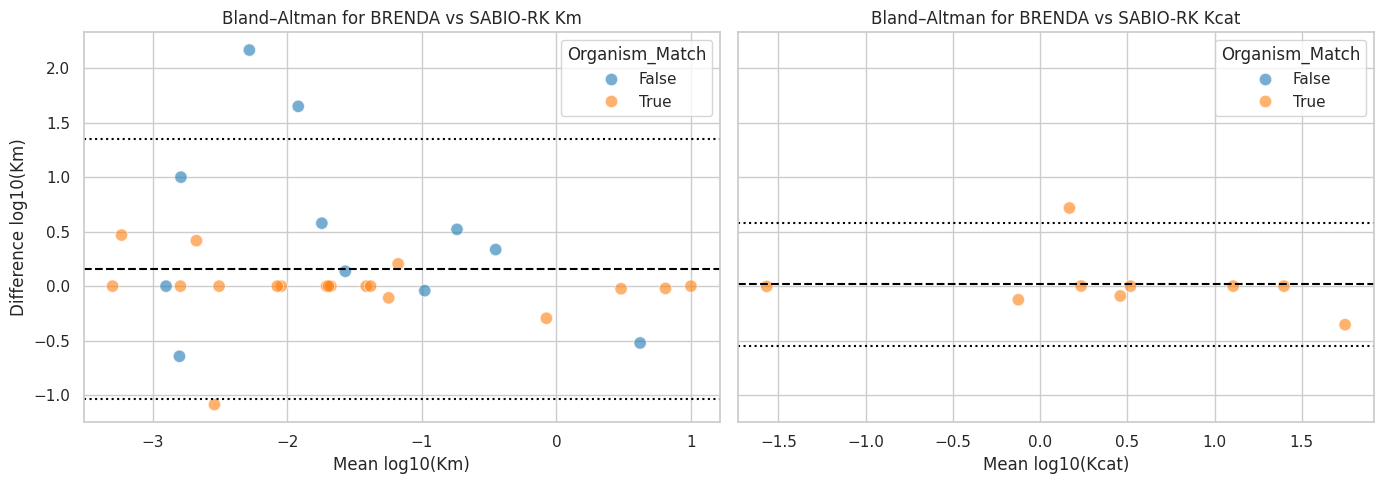

In [8]:
fig, ax = plt.subplots(1, 2, figsize = (14, 5), sharey = True)

x = np.log10(df['BRENDA_km'])
y = np.log10(df['SABIO-RK_km'])

mean_vals = (x + y) / 2
diff_vals = x - y

sns.scatterplot(x = mean_vals, y = diff_vals, hue=df['Organism_Match'], s=80, alpha=0.6, ax = ax[0], palette=['#1f77b4', '#ff7f0e'])
ax[0].axhline(diff_vals.mean(),     linestyle='--', label='Mean bias', color='black')
ax[0].axhline(diff_vals.mean() + 1.96*diff_vals.std(), linestyle=':', label='Upper LoA', color='black')
ax[0].axhline(diff_vals.mean() - 1.96*diff_vals.std(), linestyle=':', label='Lower LoA', color='black')
ax[0].set_xlabel('Mean log10(Km)') 
ax[0].set_ylabel('Difference log10(Km)')
ax[0].set_title('Bland–Altman for BRENDA vs SABIO-RK Km')

x = np.log10(df['BRENDA_kcat'])
y = np.log10(df['SABIO-RK_kcat'])

mean_vals = (x + y) / 2
diff_vals = x - y

sns.scatterplot(x = mean_vals, y = diff_vals, hue=df['Organism_Match'], s=80, alpha=0.6, ax = ax[1], palette=['#1f77b4', '#ff7f0e'])
ax[1].axhline(diff_vals.mean(),     linestyle='--', label='Mean bias', color='black')
ax[1].axhline(diff_vals.mean() + 1.96*diff_vals.std(), linestyle=':', label='Upper LoA', color='black')
ax[1].axhline(diff_vals.mean() - 1.96*diff_vals.std(), linestyle=':', label='Lower LoA', color='black')
ax[1].set_xlabel('Mean log10(Kcat)') 
ax[1].set_ylabel('Difference log10(Kcat)')
ax[1].set_title('Bland–Altman for BRENDA vs SABIO-RK Kcat')

plt.tight_layout()
plt.show()


### Bland-Altman Analysis: BRENDA vs SABIO-RK

#### **Key Observations**
- **Mean Bias (Dashed Line)**:  
  - Positive values = BRENDA measurements are higher.  
  - Negative values = SABIO-RK measurements are higher.  

- **Limits of Agreement (Dotted Lines)**:  
  - 95% of differences fall between these lines (±1.96 × SD). Narrower bands = better agreement.  

- **Organism Mismatch (Color)**:  
  - Blue: Organism annotations differ between databases.  
  - Orange: Organism annotations match.  

#### **Interpretation**  
1. **Systematic Bias**:  
   - Consistent offset between lines indicates systematic measurement differences.  
   - Example: If mean bias is +0.3 for Km, BRENDA values are ~2× higher (\(10^{0.3} ≈ 2\)).  

2. **Variability**:  
   - Wider limits of agreement (LoA) suggest poor reproducibility between databases.  

3. **Trends**:  
   - Sloping patterns (e.g., differences increasing with mean values) indicate proportional errors.  

**Takeaway**: Use to assess database consistency and identify measurement biases. Prioritize values within LoA for reliable comparisons.

#### Estimated Kinetics

In [9]:
estimated_kinetics.head()

reaction             Enzyme                     \
  Unnamed: 0_level_1               name            uniprot   
  Unnamed: 0_level_2 Unnamed: 1_level_2 Unnamed: 2_level_2   
0            rx00001               SAMS             P23686   
1            rx00002                ACS             Q9SAR0   
2            rx00003                ACO             Q9ZUN4   
3            rx00014                NaN                NaN   
4            rx00020               OMR1             Q9ZSS6   

                                                              Substrate  \
                                 amino acid sequence               name   
                                  Unnamed: 3_level_2 Unnamed: 4_level_2   
0  METFLFTSESVNEGHPDKLCDQISDAVLDACLEQDPDSKVACETCT...              L-Met   
1  MVAFATEKKQDLNLLSKIASGDGHGENSSYFDGWKAYEENPFHPID...               SAMe   
2  MVLIKEREMEIPVIDFAELDGEKRSKTMSLLDHACDKWGFFMVDNH...                ACC   
3                                                NaN           ROS\nALA   
4  MNSVQLPTAQSSLRSHIHRPSKPVVGFTHFSSRSRIAVAVLSRDET...                Thr   

                                                      \
                                      external links   
                                  Unnamed: 5_level_2   
0                                        chebi:16643   
1                                        chebi:15414   
2                                        chebi:30526   
3  chebi:16240, chebi:25935, chebi:18421, chebi:2...   
4                                        chebi:57926   

                                                                 TurNuP  \
                                SMILES/KEGG_ID/InChI        in training   
                                  Unnamed: 6_level_2 Unnamed: 7_level_2   
0                                 CSCC[C@H](N)C(O)=O                 36   
1  C[S+](CC[C@H](N)C(O)=O)C[C@H]1O[C@H]([C@H](O)[...                128   
2                                  NC1(CC1)C([O-])=O                  6   
3                                                  /                NaN   
4                   C[C@@H](O)[C@H]([NH3+])C([O-])=O                 24   

                                                                        \
   predicted Km [mM]       Kcat [1/sec] Substrate information            
  Unnamed: 8_level_2 Unnamed: 9_level_2                    EC Organism   
0               0.25               4.64                     /        /   
1               0.13              12.75                     /        /   
2               0.19               1.45                   NaN      NaN   
3                NaN                NaN                   NaN      NaN   
4               1.13               8.15                     /        /   

                                                   UniKP                      \
          Enzyme information                     Km [mM]          Kcat [1/s]   
  Km [mM]            KEGG ID Km [mM] Unnamed: 15_level_2 Unnamed: 16_level_2   
0       /                  /       /            0.235322            2.841907   
1       /                  /       /            0.062897            0.947156   
2     NaN                NaN     NaN            0.343263            0.509893   
3     NaN                NaN     NaN                /\n/                /\n/   
4       /                  /       /            0.713702            4.034947   

              CatPred                      
              Km [mM]          Kcat [1/s]  
  Unnamed: 17_level_2 Unnamed: 18_level_2  
0             0.25755             0.92153  
1             0.02869             1.29196  
2              0.1053             0.53264  
3                /\n/                /\n/  
4              4.9514              3.5794

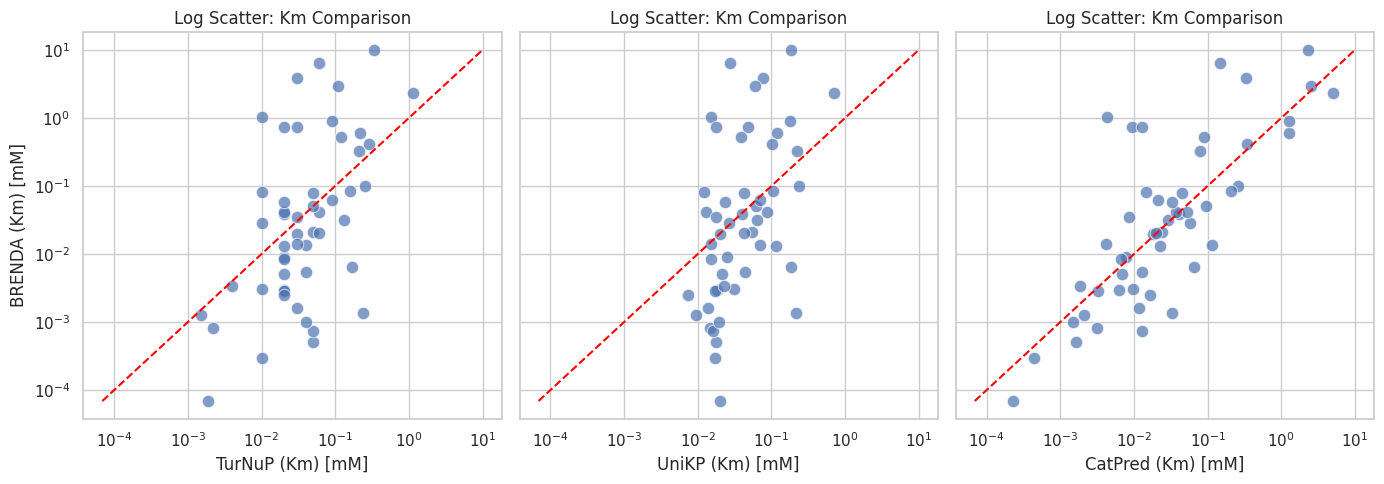

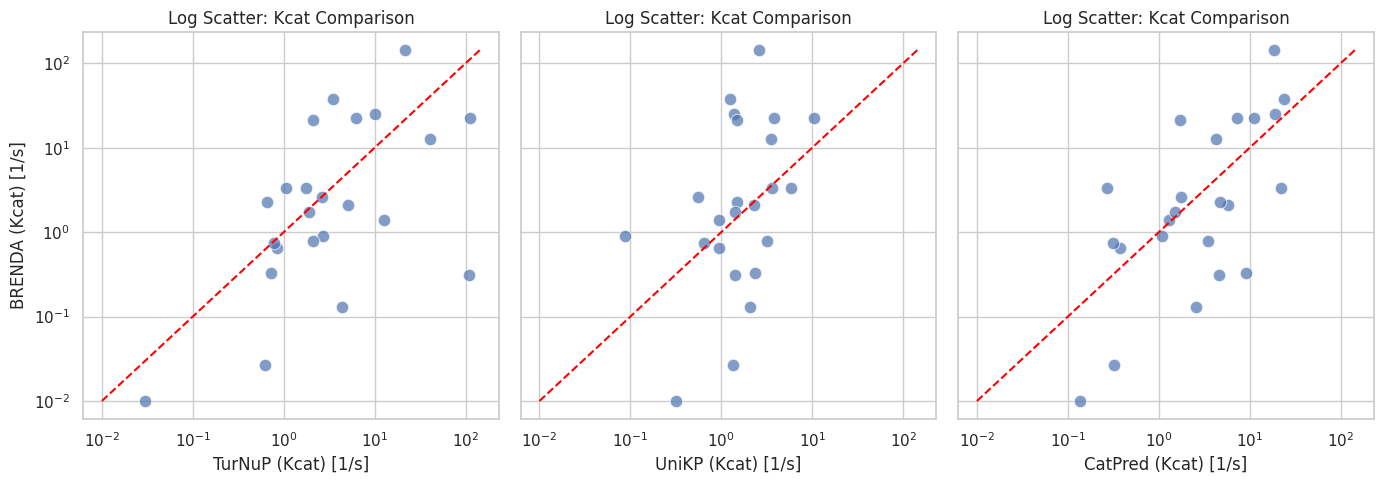

In [10]:
def create_comparison_plot(parameter, brenda_col, model_config, units, figsize=(14, 5)):
    """Create comparison plots for experimental vs predicted values."""
    fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
    
    # Data preparation
    brenda_values = pd.to_numeric(gathered_kinetics[('BRENDA', brenda_col)], errors='coerce')
    mask = ~brenda_values.isna()
    
    data_dict = {'BRENDA': brenda_values[mask]}
    for model, col in model_config.items():
        values = pd.to_numeric(estimated_kinetics[(model, col)].values.flatten(), errors='coerce')
        data_dict[model] = values[mask]
    
    df = pd.DataFrame(data_dict)

    # Create plots
    for i, (model, col) in enumerate(model_config.items()):
        sns.scatterplot(
            data=df, 
            x=model, 
            y='BRENDA', 
            s=80, 
            alpha=0.7, 
            ax=ax[i]
        )
        
        # 1:1 line
        min_val = min(df[model].min(), df['BRENDA'].min())
        max_val = max(df[model].max(), df['BRENDA'].max())
        ax[i].plot([min_val, max_val], [min_val, max_val], '--', color='red')
        
        # Axis labels and scaling
        ax[i].set_xlabel(f'{model} ({parameter}) [{units}]')
        ax[i].set_ylabel(f'BRENDA ({parameter}) [{units}]')
        ax[i].set_title(f'Log Scatter: {parameter} Comparison')
        ax[i].set_xscale('log')
        ax[i].set_yscale('log')

    plt.tight_layout()
    plt.show()

# Configuration for each parameter
plot_config = {
    'Km': {
        'brenda_col': 'km (mM)',
        'model_config': {
            'TurNuP': 'predicted Km [mM]',
            'UniKP': 'Km [mM]',
            'CatPred': 'Km [mM]'
        },
        'units': 'mM'
    },
    'Kcat': {
        'brenda_col': 'kcat (1/s)',
        'model_config': {
            'TurNuP': 'Kcat [1/sec]',
            'UniKP': 'Kcat [1/s]',
            'CatPred': 'Kcat [1/s]'
        },
        'units': '1/s'
    }
}

# Generate plots for both parameters
for param, config in plot_config.items():
    create_comparison_plot(
        parameter=param,
        brenda_col=config['brenda_col'],
        model_config=config['model_config'],
        units=config['units']
    )

In [11]:
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(parameter, brenda_col, model_config, units):
    """Calculate performance metrics for experimental vs predicted values."""
    # Prepare data
    brenda_values = pd.to_numeric(gathered_kinetics[('BRENDA', brenda_col)], errors='coerce')
    mask = ~brenda_values.isna()
    
    data_dict = {f'BRENDA_{parameter}': brenda_values[mask]}
    for model, col in model_config.items():
        values = pd.to_numeric(estimated_kinetics[(model, col)].values.flatten(), errors='coerce')
        data_dict[f'{model}_{parameter}'] = values[mask]
    
    df = pd.DataFrame(data_dict)
    
    # Calculate metrics
    results = []
    for model in model_config.keys():
        model_col = f'{model}_{parameter}'
        paired_data = df[[f'BRENDA_{parameter}', model_col]].dropna()
        
        if len(paired_data) < 2:
            print(f"Not enough data for {model} {parameter}")
            continue
            
        y_true = paired_data[f'BRENDA_{parameter}']
        y_pred = paired_data[model_col]
        
        # Pearson correlation
        r, p = pearsonr(y_true, y_pred)
        
        # Error metrics
        mae = mean_absolute_error(y_true, y_pred)
        try:
            log_rmse = np.sqrt(mean_squared_error(np.log10(y_true), np.log10(y_pred)))
        except ValueError:
            log_rmse = np.nan
        
        results.append({
            'Parameter': parameter,
            'Model': model,
            'Pearson R': r,
            'p-value': p,
            f'MAE ({units})': mae,
            'Log-RMSE': log_rmse
        })
    
    return pd.DataFrame(results)

# Configuration for metrics calculation
metric_config = {
    'Km': {
        'brenda_col': 'km (mM)',
        'model_config': {
            'TurNuP': 'predicted Km [mM]',
            'UniKP': 'Km [mM]',
            'CatPred': 'Km [mM]'
        },
        'units': 'mM'
    },
    'Kcat': {
        'brenda_col': 'kcat (1/s)',
        'model_config': {
            'TurNuP': 'Kcat [1/sec]',
            'UniKP': 'Kcat [1/s]',
            'CatPred': 'Kcat [1/s]'
        },
        'units': '1/s'
    }
}

# Calculate and combine results for all parameters
all_results = []
for param, config in metric_config.items():
    results_df = calculate_metrics(
        parameter=param,
        brenda_col=config['brenda_col'],
        model_config=config['model_config'],
        units=config['units']
    )
    all_results.append(results_df)

# Combine and format final results
final_results = pd.concat(all_results).reset_index(drop=True)
print(final_results.round(3).to_string(index=False))

Parameter   Model  Pearson R  p-value  MAE (mM)  Log-RMSE  MAE (1/s)
       Km  TurNuP      0.309    0.027     0.576     1.017        NaN
       Km   UniKP      0.245    0.083     0.591     1.063        NaN
       Km CatPred      0.507    0.000     0.500     0.742        NaN
     Kcat  TurNuP      0.107    0.627       NaN     0.861     19.937
     Kcat   UniKP      0.131    0.551       NaN     0.907     12.064
     Kcat CatPred      0.547    0.007       NaN     0.750     10.769


Key Observations

- **Km Predictions**:

    - **CatPred** performs best:

        - **Strongest correlation**: Pearson R = 0.507 (p < 0.001), indicating moderate agreement with BRENDA.

        - **Lowest errors**: MAE = 0.500 mM, Log-RMSE = 0.742.

    - **TurNuP/UniKP** show weak correlations (R = 0.309 and 0.245), with TurNuP being statistically significant (p = 0.027).

- **Kcat Predictions**:

    - **CatPred** is the only viable model:

        - **Only significant correlation**: R = 0.547 (p = 0.007), with the lowest MAE (10.769 1/s) and Log-RMSE (0.750).

    - **TurNuP/UniKP** fail:

        - No significant correlations (p > 0.5), high MAE (>12 1/s), and poor Log-RMSE (>0.85).

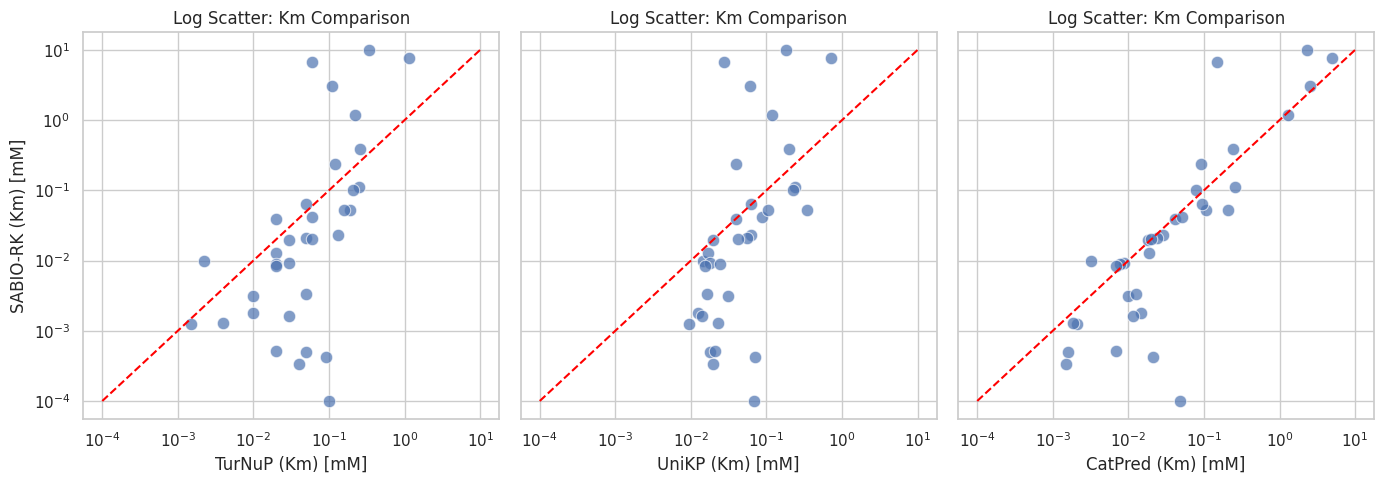

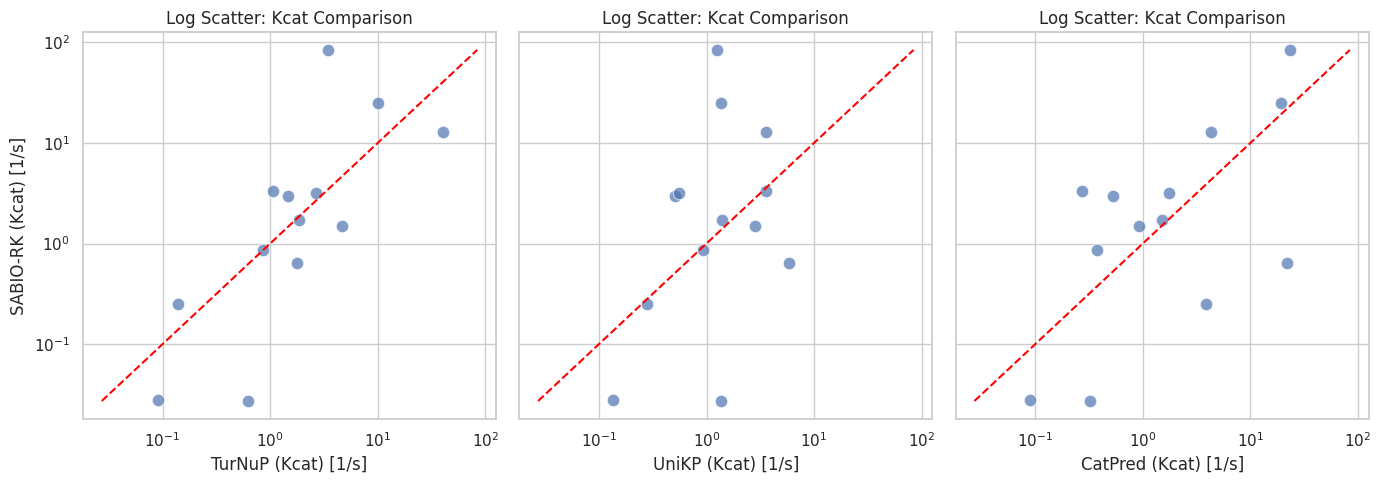

In [12]:
def create_comparison_plot(parameter, sabio_col, model_config, units, figsize=(14, 5)):
    """Create comparison plots for experimental vs predicted values."""
    fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True)
    
    # Data preparation
    sabio_values = pd.to_numeric(gathered_kinetics[('SABIO-RK', sabio_col)], errors='coerce')
    mask = ~sabio_values.isna()
    
    data_dict = {'SABIO-RK': sabio_values[mask]}
    for model, col in model_config.items():
        values = pd.to_numeric(estimated_kinetics[(model, col)].values.flatten(), errors='coerce')
        data_dict[model] = values[mask]
    
    df = pd.DataFrame(data_dict)

    # Create plots
    for i, (model, col) in enumerate(model_config.items()):
        sns.scatterplot(
            data=df, 
            x=model, 
            y='SABIO-RK', 
            s=80, 
            alpha=0.7, 
            ax=ax[i]
        )
        
        # 1:1 line
        min_val = min(df[model].min(), df['SABIO-RK'].min())
        max_val = max(df[model].max(), df['SABIO-RK'].max())
        ax[i].plot([min_val, max_val], [min_val, max_val], '--', color='red')
        
        # Axis labels and scaling
        ax[i].set_xlabel(f'{model} ({parameter}) [{units}]')
        ax[i].set_ylabel(f'SABIO-RK ({parameter}) [{units}]')
        ax[i].set_title(f'Log Scatter: {parameter} Comparison')
        ax[i].set_xscale('log')
        ax[i].set_yscale('log')

    plt.tight_layout()
    plt.show()

# Configuration for each parameter
plot_config = {
    'Km': {
        'sabio_col': 'km (mM)',
        'model_config': {
            'TurNuP': 'predicted Km [mM]',
            'UniKP': 'Km [mM]',
            'CatPred': 'Km [mM]'
        },
        'units': 'mM'
    },
    'Kcat': {
        'sabio_col': 'kcat (1/s)',
        'model_config': {
            'TurNuP': 'Kcat [1/sec]',
            'UniKP': 'Kcat [1/s]',
            'CatPred': 'Kcat [1/s]'
        },
        'units': '1/s'
    }
}

# Generate plots for both parameters
for param, config in plot_config.items():
    create_comparison_plot(
        parameter=param,
        sabio_col=config['sabio_col'],
        model_config=config['model_config'],
        units=config['units']
    )

In [13]:
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(parameter, sabio_col, model_config, units):
    """Calculate performance metrics for experimental vs predicted values."""
    # Prepare data
    sabio_values = pd.to_numeric(gathered_kinetics[('SABIO-RK', sabio_col)], errors='coerce')
    mask = ~sabio_values.isna()
    
    data_dict = {f'SABIO-RK_{parameter}': sabio_values[mask]}
    for model, col in model_config.items():
        values = pd.to_numeric(estimated_kinetics[(model, col)].values.flatten(), errors='coerce')
        data_dict[f'{model}_{parameter}'] = values[mask]
    
    df = pd.DataFrame(data_dict)
    
    # Calculate metrics
    results = []
    for model in model_config.keys():
        model_col = f'{model}_{parameter}'
        paired_data = df[[f'SABIO-RK_{parameter}', model_col]].dropna()
        
        if len(paired_data) < 2:
            print(f"Not enough data for {model} {parameter}")
            continue
            
        y_true = paired_data[f'SABIO-RK_{parameter}']
        y_pred = paired_data[model_col]
        
        # Pearson correlation
        r, p = pearsonr(y_true, y_pred)
        
        # Error metrics
        mae = mean_absolute_error(y_true, y_pred)
        try:
            log_rmse = np.sqrt(mean_squared_error(np.log10(y_true), np.log10(y_pred)))
        except ValueError:
            log_rmse = np.nan
        
        results.append({
            'Parameter': parameter,
            'Model': model,
            'Pearson R': r,
            'p-value': p,
            f'MAE ({units})': mae,
            'Log-RMSE': log_rmse
        })
    
    return pd.DataFrame(results)

# Configuration for metrics calculation
metric_config = {
    'Km': {
        'sabio_col': 'km (mM)',
        'model_config': {
            'TurNuP': 'predicted Km [mM]',
            'UniKP': 'Km [mM]',
            'CatPred': 'Km [mM]'
        },
        'units': 'mM'
    },
    'Kcat': {
        'sabio_col': 'kcat (1/s)',
        'model_config': {
            'TurNuP': 'Kcat [1/sec]',
            'UniKP': 'Kcat [1/s]',
            'CatPred': 'Kcat [1/s]'
        },
        'units': '1/s'
    }
}

# Calculate and combine results for all parameters
all_results = []
for param, config in metric_config.items():
    results_df = calculate_metrics(
        parameter=param,
        sabio_col=config['sabio_col'],
        model_config=config['model_config'],
        units=config['units']
    )
    all_results.append(results_df)

# Combine and format final results
final_results = pd.concat(all_results).reset_index(drop=True)
print(final_results.round(3).to_string(index=False))

Parameter   Model  Pearson R  p-value  MAE (mM)  Log-RMSE  MAE (1/s)
       Km  TurNuP      0.625    0.000     0.827     1.110        NaN
       Km   UniKP      0.499    0.003     0.850     1.121        NaN
       Km CatPred      0.764    0.000     0.540     0.739        NaN
     Kcat  TurNuP      0.120    0.697       NaN     0.637     10.225
     Kcat   UniKP     -0.079    0.798       NaN     0.911      9.972
     Kcat CatPred      0.686    0.010       NaN     0.770      8.352


### Comparative Analysis of BRENDA vs. SABIO-RK Model Performance

#### Key Findings

##### **Km Predictions**
| Metric          | BRENDA (Best: CatPred)        | SABIO-RK (New Results)        |
|-----------------|-------------------------------|--------------------------------|
| **Best Model**  | `CatPred`                     | `CatPred`                      |
| **Pearson R**   | 0.507 (p < 0.001)             | **0.764 (p < 0.001)**          |
| **MAE**         | 0.500 mM                      | **0.540 mM**                   |
| **Log-RMSE**    | 0.742                         | **0.739**                      |

### **Kcat Predictions**
| Metric          | BRENDA (Best: CatPred)        | SABIO-RK (New Results)         |
|-----------------|-------------------------------|---------------------------------|
| **Best Model**  | `CatPred`                     | `CatPred`                       |
| **Pearson R**   | 0.547 (p = 0.007)             | **0.686 (p = 0.010)**          |
| **MAE**         | 10.769 1/s                    | **8.352 1/s**                  |
| **Log-RMSE**    | 0.750                         | **0.770**                      |

---

#### Observations
1. **CatPred Dominance**:
   - Outperforms all models for **both databases** in:
     - Correlation strength (highest Pearson R).
     - Lowest MAE/Log-RMSE.
   - **SABIO-RK alignment**: CatPred's Km correlation improved from `0.507` (BRENDA) to `0.764`.

2. **TurNuP/UniKP Limitations**:
   - **TurNuP**: Moderate utility for SABIO-RK Km (R = 0.625) but fails for Kcat.
   - **UniKP**: Unreliable for both parameters (negative Kcat correlation for SABIO-RK: R = -0.079).

3. **SABIO-RK Advantages**:
   - Better model alignment than BRENDA (lower errors for Kcat: MAE reduced from `10.769` to `8.352 1/s`).

---

#### Recommendation for Filling Missing Values

##### **CatPred**
- **Why**:
  - Strongest agreement with SABIO-RK data (Km R = 0.764, Kcat R = 0.686).
  - Lowest errors (Km MAE = 0.540 mM, Kcat MAE = 8.352 1/s).
- **Caveats**:
  - Log-RMSE values (~0.74–0.77) imply predictions may deviate by **5–6x** from true values.
  - Validate critical predictions experimentally where possible.

